# Data Preparation

* Charging Sessions

  @Description of Fields of Charging Session Dataset
  
  *  **basic infos**  
  timezone  ——
  siteID    ——   Unique identifier for the site.   
  spaceID   ——     Unique identifier of the parking space.   
  stationID  ——   Unique identifier of the charging point.   

  *  **user level**  
  userID    ——   Unique identifier of the user, if provided.   
  userInputs  —— only available if the user participates in app-based charging.  
   
   *  **session level** 
   *  **recorded session**  /string   
   id —— Unique identifier of the session record   
   sessionID —— Unique identifier for the session.   
   
    *  **charging duration**  /datetime  
      * requested charging duration    
        modifiedAt  —— Time this user input was provided.   
        requestedDeparture —— User estimated departure time. 
        minutesAvailable —— Length of the session as estimated by the user.   
      * recorded charging duration   
        connectionTime —— Time when the EV plugged in.   
        disconnectTime —— Time when the EV unplugged.   
        doneChargingTime —— Time of the last non-zero current draw recorded.   
    
    *  **charging energy and driving range**  /float  
      * requested charging energy and driving range  
        kWhRequested —— Energy requested by the user in kWh.   
        milesRequested —— Number of miles requested by the user.     
      * recorded charging energy  
        kWhDelivered —— Amount of energy delivered during the session.  
      * Efficiency  
        WhPerMile —— Efficiency of the EV in Wh per mile.   

    *  **payment**  /bool  
     paymentRequired —— If the user was required to pay for this session.   

    



In [77]:
import pandas as pd
import ast

# charging data process
charging_sessions = pd.read_csv(
    "Data Share/charging_sessions.csv",
    index_col=0,
    dtype={"userID": str, "siteID": str}
)

# userInputs 
user_inputs = charging_sessions["userInputs"].fillna("[]").apply(
lambda x: ast.literal_eval(x)
).apply(
    lambda x: x[0] if x else {}
)

user_inputs = pd.DataFrame(
    user_inputs.tolist(),
    index=charging_sessions.index
).add_prefix("input_")

charging_sessions = charging_sessions.drop(columns=["userInputs"]).join(user_inputs)

charging_sessions = charging_sessions[[
    'timezone', 'siteID', 'spaceID', 'stationID',
    'userID', 'input_userID', 'id', 'sessionID',
    'input_modifiedAt', 'input_requestedDeparture', 'input_minutesAvailable',
    'connectionTime', 'disconnectTime', 'doneChargingTime', 
    'input_kWhRequested', 'input_milesRequested', 'kWhDelivered',
    'input_WhPerMile', 'input_paymentRequired'
    ]]

for column in ["connectionTime", "disconnectTime", "doneChargingTime"]:
    charging_sessions[column] = pd.to_datetime(charging_sessions[column], utc=True)

# Calculate session durations in hours.
charging_sessions["connected_duration_hours"] = (
    (
    charging_sessions["disconnectTime"] - charging_sessions["connectionTime"]
    ).dt.total_seconds() / 3600
).round(1)

charging_sessions["charging_duration_hours"] = (
    (
    charging_sessions["doneChargingTime"] - charging_sessions["connectionTime"]
    ).dt.total_seconds() / 3600
).round(1)

In [78]:
# weather
weather = pd.read_csv('Data Share/weather_burbank_airport.csv')
weather["timestamp"] = pd.to_datetime(weather["timestamp"])

 Data Quality Overview

In [79]:
def column_summary(frame):
    """Summarize data types and missing values for every column."""
    return pd.DataFrame({
        "Data type": frame.dtypes.astype(str),
        "Missing values": frame.isna().sum(),
        "Missing (%)": (frame.isna().mean() * 100).round(2),
    }).rename_axis("Column")

print("Charging sessions")
display(column_summary(charging_sessions))
print("weather")
display(column_summary(weather))

print("Duplicate charging session IDs:", charging_sessions["sessionID"].duplicated().sum())
print("Duplicate weather rows:", weather.duplicated().sum())
print("Charging sessions by site ID:")
display(charging_sessions["siteID"].value_counts().rename("Sessions").to_frame())

Charging sessions


,Data type,Missing values,Missing (%)
Column,,,
timezone,object,0,0.00
siteID,object,0,0.00
spaceID,object,0,0.00
stationID,object,0,0.00
userID,object,95558,22.62
input_userID,float64,95558,22.62
id,object,0,0.00
sessionID,object,0,0.00
input_modifiedAt,object,95558,22.62


weather


,Data type,Missing values,Missing (%)
Column,,,
city,object,0,0.00
timestamp,datetime64[ns],0,0.00
temperature,float64,25,0.09
cloud_cover,float64,20,0.07
cloud_cover_description,object,20,0.07
pressure,float64,8,0.03
windspeed,float64,86,0.29
precipitation,float64,0,0.00
felt_temperature,float64,26,0.09


Duplicate charging session IDs: 357375
Duplicate weather rows: 0
Charging sessions by site ID:


,Sessions
siteID,
0001,245238
0002,175093
2,2081


  ### Notes for Further Preparation

- Confirm the weather timestamp timezone before joining weather observations to UTC charging timestamps.
- Weather coverage ends before charging session coverage, so later charging sessions will not have matching weather observations.
- Missing values are reported above and have not been filled or removed.


## Data Explore

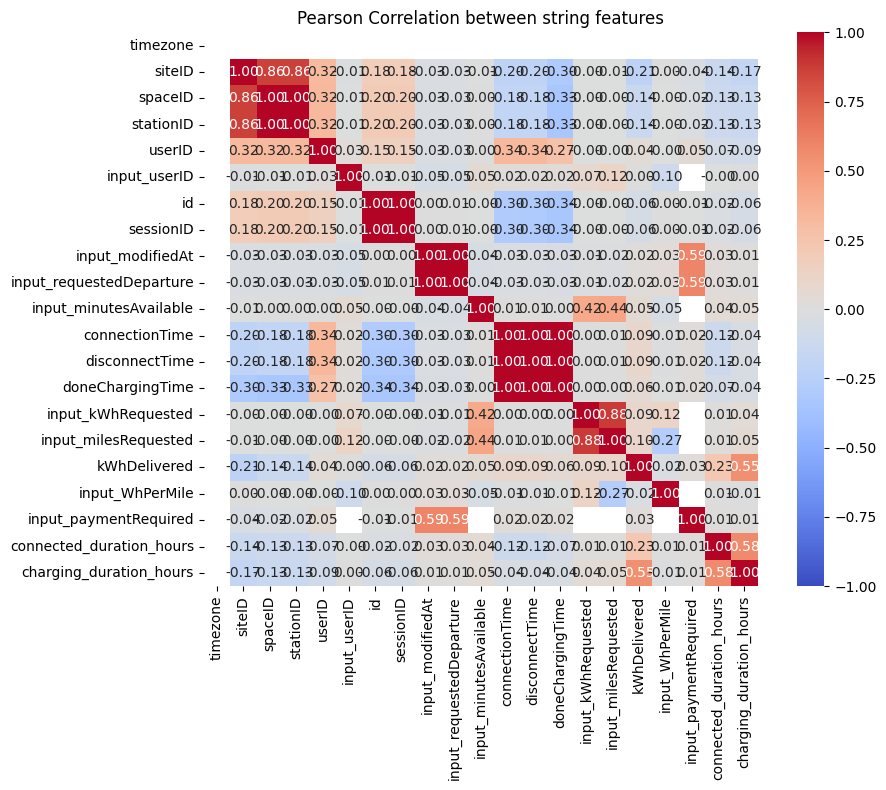

,level_0,level_1,Pearson r
0,siteID,spaceID,0.861698
1,siteID,stationID,0.861698
19,spaceID,stationID,1.000000
84,id,sessionID,1.000000
111,input_modifiedAt,input_requestedDeparture,0.999888
143,connectionTime,disconnectTime,1.000000
144,connectionTime,doneChargingTime,1.000000
152,disconnectTime,doneChargingTime,1.000000
167,input_kWhRequested,input_milesRequested,0.877826


In [ ]:
# 1st check, check relationship
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

charging_encoded = charging_sessions.copy()

string_columns = charging_encoded.select_dtypes(
    include=["object", "string"]
).columns

for column in string_columns:
    charging_encoded[column] = pd.factorize(
        charging_encoded[column]
    )[0]

correlation = charging_encoded.corr(method="pearson")

# Plot the correlation heatmap.
plt.figure(figsize=(10, 8))
sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True
)
plt.title("Pearson Correlation between string features")
plt.tight_layout()
plt.show()

# Keep only the upper triangle.
pairs = correlation.where(
    np.triu(np.ones(correlation.shape), k=1).astype(bool)
).stack().rename("Pearson r").reset_index()

display(pairs[pairs["Pearson r"] > 0.8])

In [81]:
# 1st check, check relationship
from itertools import combinations
#print("1st review of charging sessions")
summary = charging_sessions.describe(include="all").T
summary["unique"] = charging_sessions.nunique()
# display(summary.T)

# Count unique mappings in both directions.
def relationship_check(data, column_a, column_b):
    # Check both directions separately.
    for source, target in [(column_a, column_b), (column_b, column_a)]:
        counts = data.groupby(source)[target].nunique()

        if counts.empty:
            print(f"{source} → {target}: no data to check!")
        elif counts.eq(1).all():
            print(f"1 {source} -> 1 {target}")
        else:
            if counts.gt(1).any():
                print(f"{source} -> multiple {target}:")
                # display(counts[counts > 1].to_frame(f"{target}_count"))

            if counts.eq(0).any():
                print(f"some {source} values have no {target}:")
                # display(counts[counts == 0].to_frame(f"{target}_count"))

    print("*********")


columns = ["siteID", "spaceID", "stationID", "userID", "input_userID"]

# Check every pair of ID columns.
for column_a, column_b in combinations(columns, 2):
    relationship_check(charging_sessions, column_a, column_b)
    print()
    
relationship_check(charging_sessions, 'id', 'sessionID')
relationship_check(charging_sessions, 'connectionTime', 'disconnectTime')
relationship_check(charging_sessions, 'connectionTime', 'doneChargingTime')


siteID -> multiple spaceID:
spaceID -> multiple siteID:
*********

siteID -> multiple stationID:
stationID -> multiple siteID:
*********

siteID -> multiple userID:
userID -> multiple siteID:
*********

siteID -> multiple input_userID:
input_userID -> multiple siteID:
*********

1 spaceID -> 1 stationID
1 stationID -> 1 spaceID
*********

spaceID -> multiple userID:
some spaceID values have no userID:
userID -> multiple spaceID:
*********

spaceID -> multiple input_userID:
input_userID -> multiple spaceID:
*********

stationID -> multiple userID:
some stationID values have no userID:
userID -> multiple stationID:
*********

stationID -> multiple input_userID:
input_userID -> multiple stationID:
*********

userID -> multiple input_userID:
input_userID -> multiple userID:
*********

1 id -> 1 sessionID
1 sessionID -> 1 id
*********
connectionTime -> multiple disconnectTime:
disconnectTime -> multiple connectionTime:
*********
connectionTime -> multiple doneChargingTime:
some connectionTi

siteID -> multiple spaceID or stationID    
        1 spaceID <-> 1 siteID   
multiple siteID <-> multiple userID   
multiple spaceID <-> multiple or non userID      
multiple userID <-> multiple input_userID    
1 id <->  1 sessionID

In [82]:
# data cleaning
# site ID
charging_sessions["siteID"] = charging_sessions["siteID"].replace({
    "0001": "1",
    "0002": "2"
}).astype("Int64")

# duplicate feature
charging_sessions = charging_sessions.drop(columns=["spaceID", 'id', 'timezone'])

for column in ["stationID", "userID", "input_userID", "sessionID"]:
    codes = pd.factorize(charging_sessions[column])[0]
    charging_sessions[column] = pd.Series(
        codes, index=charging_sessions.index
    ).replace(-1, float("nan"))

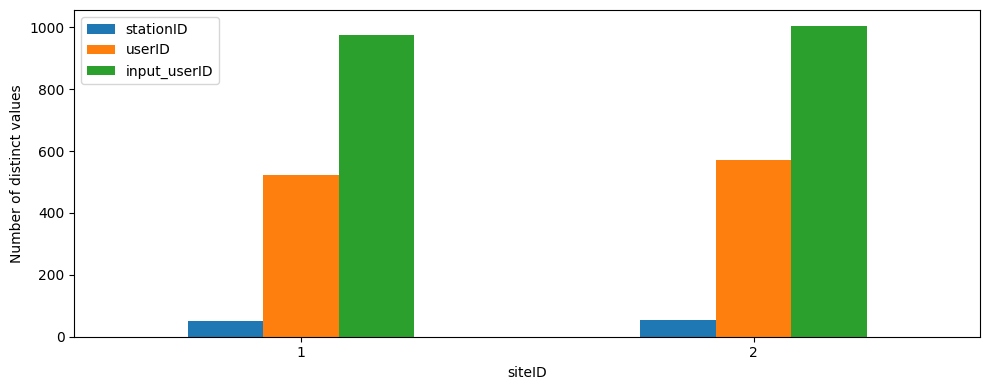

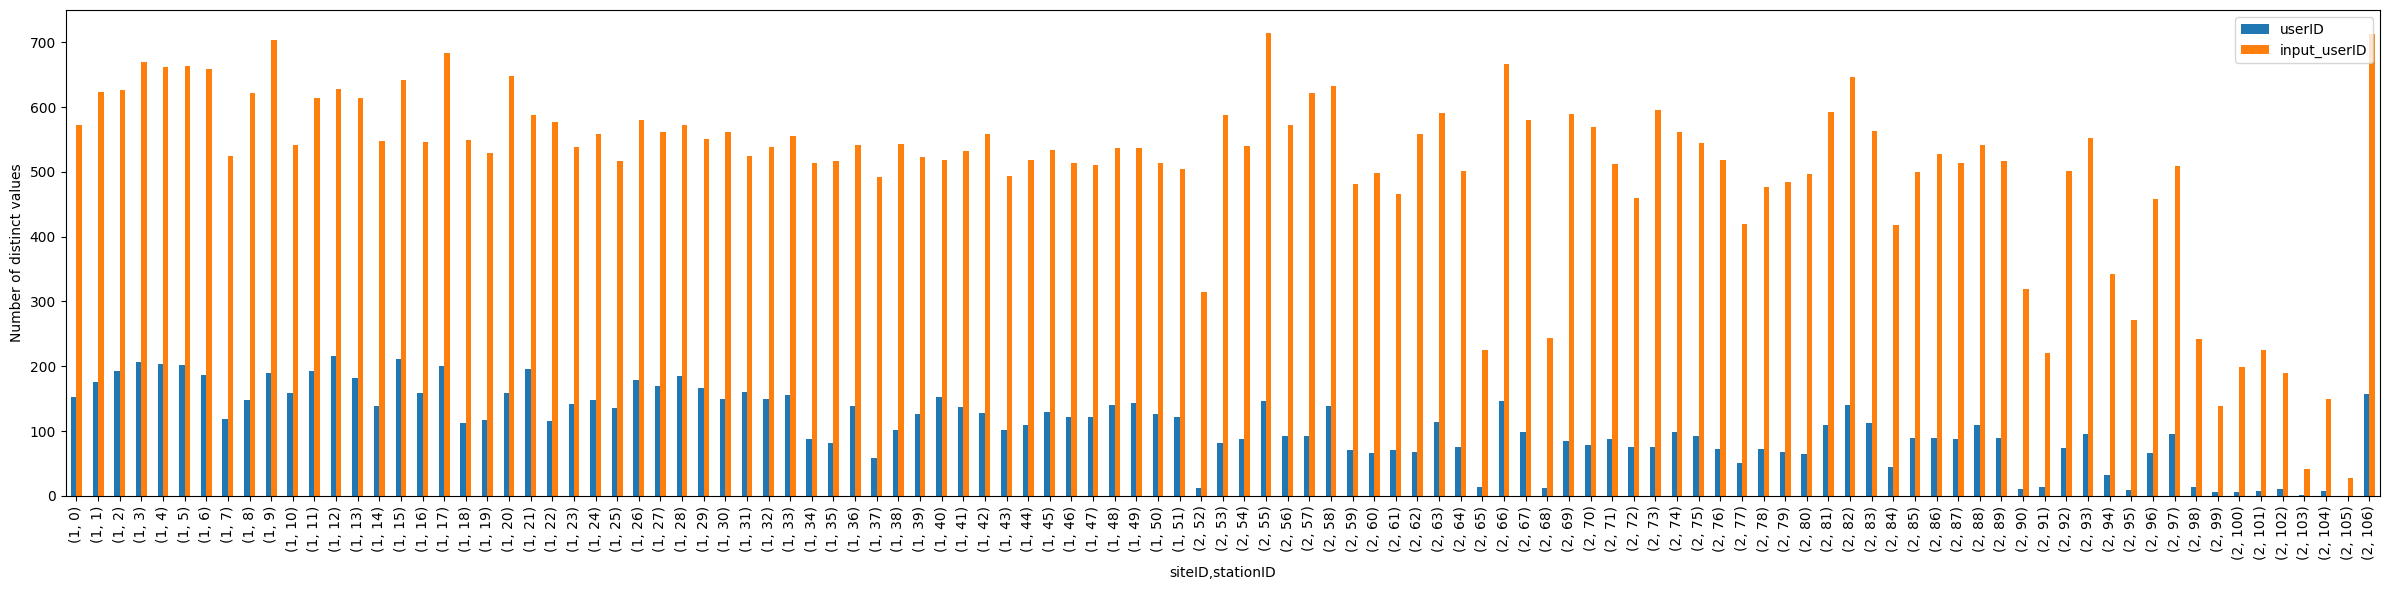

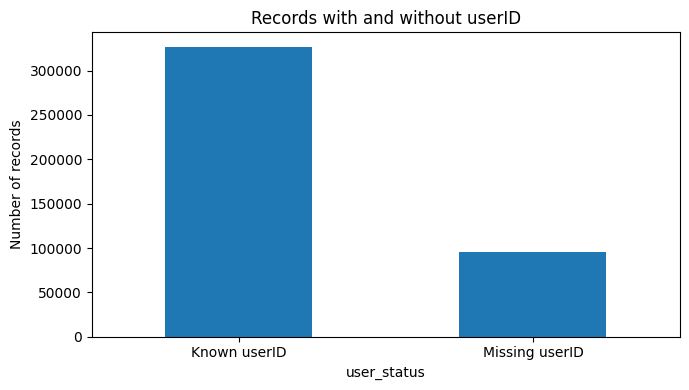

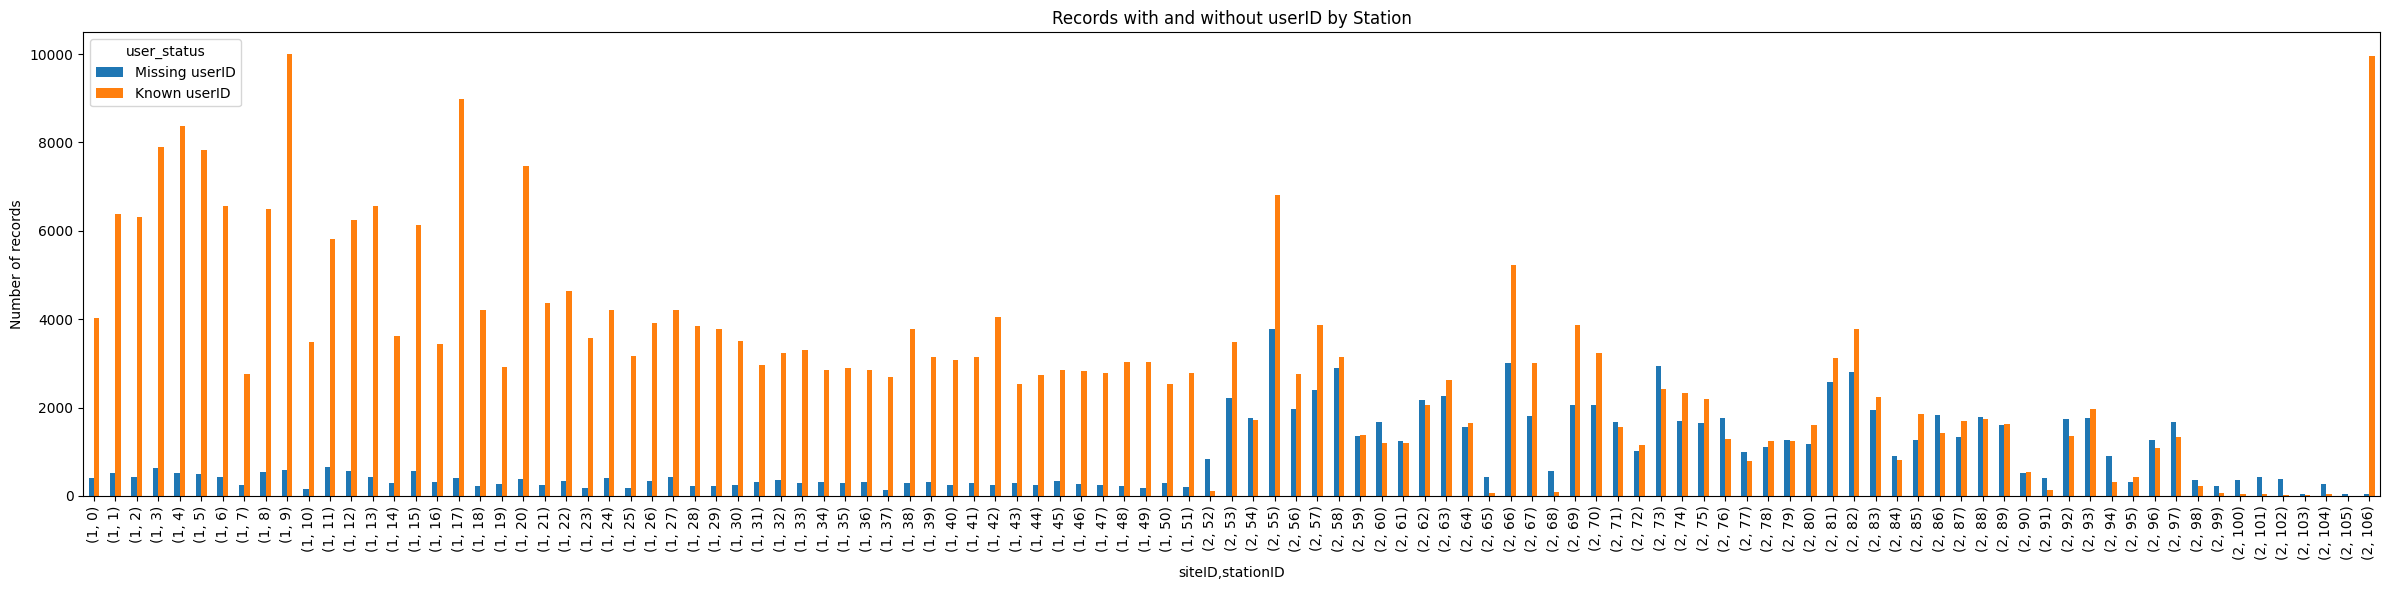

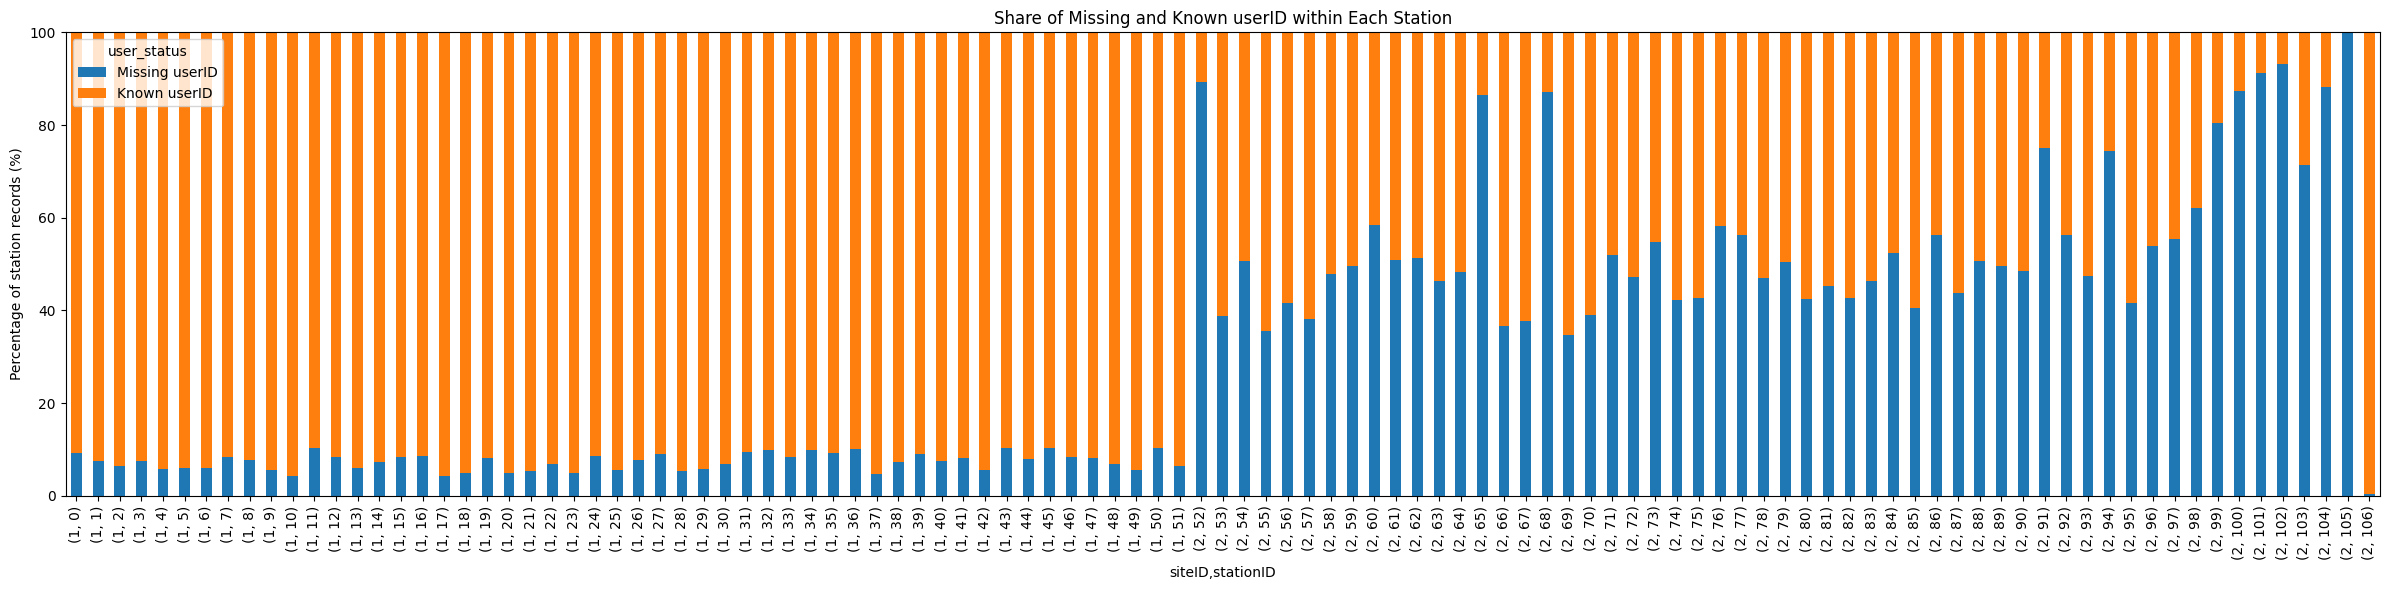

In [83]:
# 2nd check - check for charging location
# Group progressively by site, station, and user.
import matplotlib.pyplot as plt

# Plot by Location
# plot distinct stations and users per site.
charging_sessions.groupby("siteID", sort=False, dropna=False)[
    ["stationID", "userID", "input_userID"]
].nunique().plot.bar(figsize=(10, 4))

plt.ylabel("Number of distinct values")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# plot distinct users per station within each site.
charging_sessions.groupby(["siteID", "stationID"], sort=False, dropna=False)[
    ["userID", "input_userID"]
].nunique().plot.bar(figsize=(24, 6))

plt.ylabel("Number of distinct values")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

# Plot by whether userID is missing.
data = charging_sessions.assign(
    user_status=charging_sessions["userID"].isna().map({
        True: "Missing userID",
        False: "Known userID"
    })
)

# Compare overall record counts.
data["user_status"].value_counts().plot.bar(
    figsize=(7, 4), rot=0
)
plt.ylabel("Number of records")
plt.title("Records with and without userID")
plt.tight_layout()
plt.show()

# Count records by site, station, and user status.
station_counts = data.groupby(
    ["siteID", "stationID", "user_status"],
    sort=False,
    dropna=False,
    observed=True
).size().unstack("user_status", fill_value=0)

station_counts = station_counts.reindex(
    columns=["Missing userID", "Known userID"], fill_value=0
)

# Compare record counts at each station.
station_counts.plot.bar(figsize=(24, 6))
plt.ylabel("Number of records")
plt.title("Records with and without userID by Station")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

# Compare percentages within each station.
station_percent = station_counts.div(
    station_counts.sum(axis=1), axis=0
) * 100

station_percent.plot.bar(stacked=True, figsize=(24, 6))
plt.ylabel("Percentage of station records (%)")
plt.title("Share of Missing and Known userID within Each Station")
plt.ylim(0, 100)
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [84]:
charging_sessions

,siteID,stationID,userID,input_userID,sessionID,input_modifiedAt,input_requestedDeparture,input_minutesAvailable,connectionTime,disconnectTime,doneChargingTime,input_kWhRequested,input_milesRequested,kWhDelivered,input_WhPerMile,input_paymentRequired,connected_duration_hours,charging_duration_hours
0,1,0,0.0,0.0,0,"Thu, 02 Jan 2020 13:09:39 GMT","Thu, 02 Jan 2020 20:51:54 GMT",463.0,2020-01-02 13:08:54+00:00,2020-01-02 19:11:15+00:00,2020-01-02 17:31:35+00:00,25.0,100.0,25.016,250.0,True,6.0,4.4
0,1,0,0.0,1.0,0,"Tue, 02 Jul 2019 00:32:53 GMT","Tue, 02 Jul 2019 02:02:46 GMT",90.0,2020-01-02 13:08:54+00:00,2020-01-02 19:11:15+00:00,2020-01-02 17:31:35+00:00,4.0,20.0,25.016,200.0,True,6.0,4.4
0,1,0,0.0,2.0,0,"Sat, 02 Jan 2021 21:42:04 GMT","Sun, 03 Jan 2021 01:12:05 GMT",210.0,2020-01-02 13:08:54+00:00,2020-01-02 19:11:15+00:00,2020-01-02 17:31:35+00:00,18.6,60.0,25.016,310.0,True,6.0,4.4
0,1,0,0.0,NaN,0,NaN,NaN,NaN,2020-01-02 13:08:54+00:00,2020-01-02 19:11:15+00:00,2020-01-02 17:31:35+00:00,NaN,NaN,25.016,NaN,NaN,6.0,4.4
0,1,0,0.0,NaN,0,NaN,NaN,NaN,2020-01-02 13:08:54+00:00,2020-01-02 19:11:15+00:00,2020-01-02 17:31:35+00:00,NaN,NaN,25.016,NaN,NaN,6.0,4.4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10086,1,45,152.0,NaN,6984,NaN,NaN,NaN,2019-07-31 19:19:47+00:00,2019-08-01 00:34:51+00:00,2019-07-31 21:25:30+00:00,NaN,NaN,11.589,NaN,NaN,5.3,2.1
10086,1,45,152.0,255.0,6984,"Wed, 31 Jul 2019 19:20:10 GMT","Wed, 31 Jul 2019 20:19:47 GMT",60.0,2019-07-31 19:19:47+00:00,2019-08-01 00:34:51+00:00,2019-07-31 21:25:30+00:00,22.0,80.0,11.589,275.0,True,5.3,2.1
10087,1,6,NaN,299.0,6985,"Wed, 04 Dec 2019 20:58:35 GMT","Thu, 05 Dec 2019 00:54:43 GMT",237.0,2019-07-31 19:21:47+00:00,2019-07-31 22:00:04+00:00,2019-07-31 20:51:34+00:00,20.0,50.0,0.897,400.0,True,2.6,1.5
10087,1,6,NaN,NaN,6985,NaN,NaN,NaN,2019-07-31 19:21:47+00:00,2019-07-31 22:00:04+00:00,2019-07-31 20:51:34+00:00,NaN,NaN,0.897,NaN,NaN,2.6,1.5


In [114]:
# Encode categorical columns; represent missing values separately.
charging_encoded = pd.get_dummies(
    charging_sessions,
    columns=string_columns,
    dummy_na=True,
    dtype=int
)

display(charging_encoded.head())
for level in range(1, len(group_columns) + 1):
    columns = group_columns[:level]

    summary = charging_sessions.groupby(columns, dropna=False).agg(
        session_count=("sessionID", "size"),
        mean_connected_hours=("connected_duration_hours", "mean"),
        mean_charging_hours=("charging_duration_hours", "mean"),
        valid_charging_duration_count=("charging_duration_hours", "count"),
        mean_energy_kWh=("kWhDelivered", "mean")
    ).reset_index()

    group_results[level] = summary

    print("Grouped by:", ", ".join(columns))
    display(summary)

Grouped by: siteID


,siteID,session_count,mean_connected_hours,mean_charging_hours,valid_charging_duration_count,mean_energy_kWh
0,1,245238,6.854552,4.026198,229250,13.984802
1,2,177174,5.526096,2.951376,160506,9.429465


Grouped by: siteID, stationID


,siteID,stationID,session_count,mean_connected_hours,mean_charging_hours,valid_charging_duration_count,mean_energy_kWh
0,1,1-1-178-817,6991,6.972965,4.540553,6579,15.830241
1,1,1-1-178-823,10575,5.776728,3.086122,9908,9.533009
2,1,1-1-178-824,6808,6.651484,4.226468,6351,14.960698
3,1,1-1-178-828,9390,5.756581,3.379015,8897,11.482839
4,1,1-1-179-777,4617,7.031016,4.021652,4286,14.404063
...,...,...,...,...,...,...,...
102,2,2-39-91-441,2417,6.221266,2.870354,2314,11.463804
103,2,2-39-92-436,3122,6.145740,2.467740,3013,9.062184
104,2,2-39-92-442,2778,6.811483,3.373884,2665,14.807902
105,2,2-39-95-27,4033,6.993752,3.108948,3867,10.012435


Grouped by: siteID, stationID, userID


,siteID,stationID,userID,session_count,mean_connected_hours,mean_charging_hours,valid_charging_duration_count,mean_energy_kWh
0,1,1-1-178-817,000000076,22,1.854545,1.800000,22,6.883000
1,1,1-1-178-817,000000169,7,9.300000,3.400000,7,8.184000
2,1,1-1-178-817,000000171,29,3.765517,2.444828,29,12.049103
3,1,1-1-178-817,000000176,111,9.528829,5.574194,93,15.192955
4,1,1-1-178-817,000000183,4,1.500000,1.500000,4,9.289000
...,...,...,...,...,...,...,...,...
11685,2,2-39-95-444,000003600,2,3.500000,1.800000,2,5.761000
11686,2,2-39-95-444,000003751,4,0.300000,0.300000,4,0.878000
11687,2,2-39-95-444,000005594,9,7.600000,NaN,0,6.313000
11688,2,2-39-95-444,000006435,9,2.300000,2.300000,9,8.509000


Grouped by: siteID, stationID, userID, input_userID


,siteID,stationID,userID,input_userID,session_count,mean_connected_hours,mean_charging_hours,valid_charging_duration_count,mean_energy_kWh
0,1,1-1-178-817,000000076,76.0,4,1.725000,1.65000,4,6.46675
1,1,1-1-178-817,000000076,362.0,1,3.400000,3.40000,1,10.35400
2,1,1-1-178-817,000000076,425.0,1,3.400000,3.40000,1,10.35400
3,1,1-1-178-817,000000076,697.0,1,1.000000,1.00000,1,5.63200
4,1,1-1-178-817,000000076,744.0,1,3.400000,3.40000,1,10.35400
...,...,...,...,...,...,...,...,...,...
227723,2,2-39-95-444,NaN,13573.0,1,8.700000,5.80000,1,15.61200
227724,2,2-39-95-444,NaN,13646.0,1,8.000000,4.70000,1,8.01500
227725,2,2-39-95-444,NaN,17752.0,1,5.300000,5.10000,1,8.28700
227726,2,2-39-95-444,NaN,19139.0,1,1.100000,1.10000,1,2.15000
